# 21 — From John Snow’s map to GeoAI

**Can a model find nearby groups before we reveal the pumps?**

Use the [five-minute presentation walkthrough](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/presentations/cholera-five-minutes.html) first. It has saved views for a talk; this notebook performs the actual Python calculations. Run cells from top to bottom with **Shift+Enter**. No AI account, API key, Ollama or live outbreak-data service is needed.

**JupyterLite** runs the Python workbench in your browser. **DBSCAN** supplies a small machine-learning method. **GeoLibre** provides an optional interactive map. The tile-free analytical views work even when the external map viewer is unavailable, after the notebook and packages have loaded.

Historical teaching data, not a contemporary surveillance dataset. Do not replace it with patient addresses in this public site.


## Start here: the question behind the code

**Can a model find nearby groups before we reveal the pumps?**

**What you will learn:** map → group → reveal → question. The numbered reading guides below follow the actual code cells. Read a guide, predict the output, then run its cell with **Shift+Enter**. Run from top to bottom; changing an upstream value requires rerunning the cells that use it.

**GeoAI connection:** Unsupervised DBSCAN fits geographic location groups; mapping and pump overlays are separate steps. This is not causal inference.

**Why this is useful:** A small experiment makes inputs, model choices, map context and limits visible to a first-time audience.

**Where the work happens:** Pyodide computes with bundled historical data. Plots need no tiles; optional GeoLibre viewing uses its hosted application and basemap.

![From John Snow’s map to GeoAI. Inspect 250 historical locations before fitting any model. Find location groups using a geographic distance and a chosen neighborhood size. Add pumps as context after fitting; they were not model inputs. Change the distance and ask what additional evidence an investigation needs.](assets/learning/21/infographic.svg)

### Watch the idea unfold

[![Preview: From John Snow’s map to GeoAI — 32-second captioned walkthrough](assets/learning/21/poster.png)](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/21/watch.html)

[▶ Watch the captioned mini-video and read its transcript](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/21/watch.html) · [Launch this notebook](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/lab/index.html?path=21_cholera_geoai_first_steps.ipynb) · [Read this Book chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/notebooks/21_cholera_geoai_first_steps.html) · [Python and browser learning guide](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/learning-guide.html)

The video is a silent four-step teaching storyboard with player controls and captions. Open the companion page to play, pause, seek or download it. The local copy is bundled under `assets/learning/21/`; downloaded media can be played offline. The infographic and the text below cover the same ideas without a video player.

**Video transcript:**

1. **Map (0–8 s):** Inspect 250 historical locations before fitting any model. Code landmark: `load_records()`.

2. **Group (8–16 s):** Find location groups using a geographic distance and a chosen neighborhood size. Code landmark: `DBSCAN(...).fit_predict(...)`.

3. **Reveal (16–24 s):** Add pumps as context after fitting; they were not model inputs. Code landmark: `plot_locations(..., pumps=pumps)`.

4. **Question (24–32 s):** Change the distance and ask what additional evidence an investigation needs. Code landmark: `radius_control`.


### Code guide 1 — Prepare a small browser experiment

**Read the Python:** `import` loads tools. In Pyodide, `await loadPackage` waits for compiled scientific packages; micropip adds notebook controls. This cell does not fetch outbreak data or contact an AI service.

**Look for:** Python, plots, widgets and the bundled lesson helper are ready.

**Pause and try:** Run this cell before the presentation; a first package download needs internet access.


In [1]:
import sys
if sys.platform == "emscripten":
    from pyodide_js import loadPackage
    await loadPackage(["numpy", "pandas", "matplotlib", "scikit-learn", "micropip"])
    import micropip
    await micropip.install("ipywidgets")
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from sklearn.cluster import DBSCAN
from IPython.display import display, clear_output
from cholera_demo import (load_records, cluster_locations, summary,
                          plot_locations, geolibre_map, EARTH_RADIUS_M)
print("Tools ready. No model has been fitted yet.")


Tools ready. No model has been fitted yet.


## 1. Map the evidence

**Say:** “These dots show where deaths were recorded. What do you notice?” One dot represents a location, not a person. These files contain 250 locations, 489 recorded deaths and eight pumps; those are not claims about the complete outbreak. The location map deliberately has no street basemap and does not yet show pumps.


### Code guide 2 — Map the evidence before fitting a model

**Read the Python:** `load_records` reads two bundled CSVs. `len` counts locations; `sum` totals the DEATHS column. The point map uses equal-size symbols, one per recorded location, not one per person.

**Look for:** 250 locations, 489 recorded deaths and eight pumps; only the death locations are drawn so far.

**Pause and try:** Describe a pattern you see without claiming what caused it.


250 locations | 489 recorded deaths | 8 pumps


,FID,DEATHS,LON,LAT
0,0,3,-0.137930,51.513418
1,1,2,-0.137883,51.513361
2,2,1,-0.137853,51.513317
3,3,1,-0.137812,51.513262
4,4,4,-0.137767,51.513204


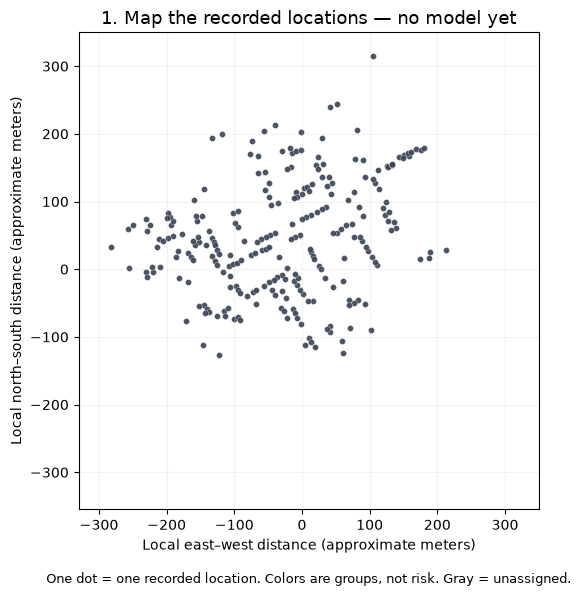

In [2]:
deaths, pumps = load_records()
print(f"{len(deaths)} locations | {int(deaths.DEATHS.sum())} recorded deaths | {len(pumps)} pumps")
display(deaths.head())
baseline_figure = plot_locations(deaths)
plt.show()


## 2. Add one machine-learning step

**Say:** “Now let a model group nearby locations. We have not told it where the pumps are.”

DBSCAN is unsupervised learning: no correct-group labels are supplied. A core neighborhood needs at least **five locations, including itself**, within the chosen distance. Connected neighborhoods can form a group much wider than that distance. Sparse observations may be unassigned (`-1`); this does not mean they are errors or unimportant.

The inputs are coordinates only. `DEATHS` is **not** a training weight. A building with one recorded death and a building with several each contribute one location. We are exploring recorded-location density, **not population-adjusted risk**. The pump table is not passed to the model.


### Code guide 3 — Fit the geographic clustering model

**Read the Python:** `np.radians` converts latitude/longitude for the haversine distance. `eps` expresses a chosen meter radius as an angle. `min_samples=5` includes the point itself. `fit_predict` computes group membership from locations, without pump coordinates or DEATHS weights.

**Look for:** At 50 meters, one group has 243 locations; seven are unassigned. Group numbers are labels, not risk scores.

**Pause and try:** Why is a 50-meter neighbor distance not a 50-meter maximum cluster diameter?


,group,locations,recorded_deaths
0,-1,7,10
1,0,243,479


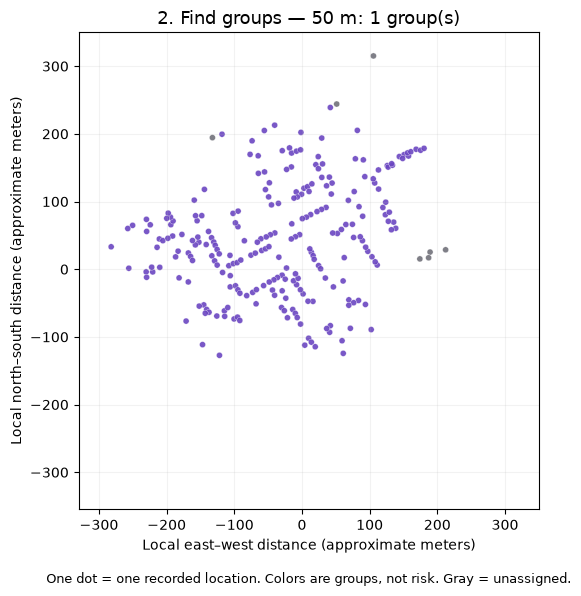

In [3]:
radius_m = 50  # Chosen teaching setting, not an estimated disease-transmission distance.
coordinates_radians = np.radians(deaths[["LAT", "LON"]].to_numpy())
labels = DBSCAN(eps=radius_m / EARTH_RADIUS_M, min_samples=5,
                metric="haversine", algorithm="brute").fit_predict(coordinates_radians)
display(summary(deaths, labels))  # DEATHS is summed only after fitting.
group_figure = plot_locations(deaths, labels, radius_m=radius_m)
plt.show()


## 3. Reveal the pumps, then ask a better question

**Say:** “Which places would you investigate, and what other evidence would you need?” This cell reuses the existing labels; it does not refit or rank pumps. P1 is the source table's Broadwick Street record, associated with the historical Broad Street setting. Source names are preserved rather than supplied to the model as an answer.


### Code guide 4 — Reveal context without retraining

**Read the Python:** The same `labels` are plotted with pumps added as context. Pump names are read from the source table. No model-fitting call occurs in this cell.

**Look for:** Pump markers P1–P8 beside the existing groups; no predicted source of infection.

**Pause and try:** What interviews or water-use evidence would you seek before drawing a conclusion?


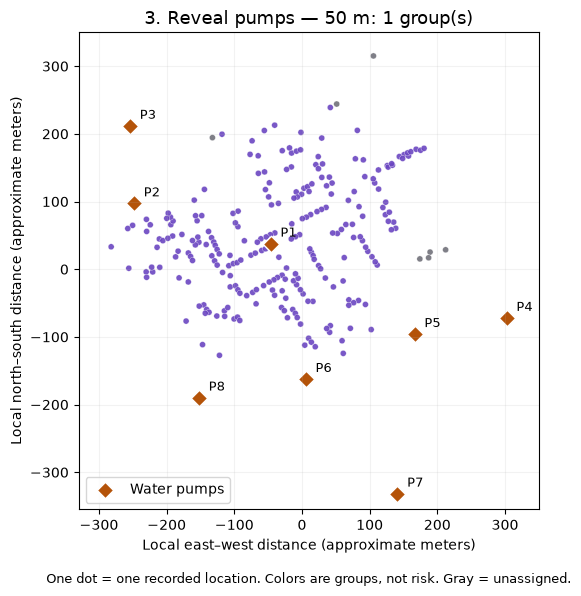

,map_label,Street
0,P1,Broadwick Street
1,P2,Kingly Street
2,P3,Ramillies Place
3,P4,Dean Street
4,P5,Rupert Street
5,P6,Bridle Lane
6,P7,Regent Street
7,P8,Warwick Street


In [4]:
reveal_figure = plot_locations(deaths, labels, pumps=pumps, radius_m=radius_m)
plt.show()
display(pumps.assign(map_label=[f"P{i}" for i in range(1, len(pumps)+1)])[["map_label", "Street"]])


## 4. Change one setting and watch the result

Try **50 → 25 → 100 meters**. The gray points are unassigned at that setting. Colors and group numbers are arbitrary identifiers, not severity categories or stable identities across settings. A model that puts almost everything into one group may be a poor investigation aid.

This slider runs **real DBSCAN fits in Python**. Unlike the Book's saved-results presentation, it recalculates when you change the distance. The checkbox only changes whether pumps appear.


### Code guide 5 — Change one assumption

**Read the Python:** The slider has three distance choices. Its callback reruns DBSCAN and replaces the plot. The checkbox only shows or hides pumps. Matplotlib draws the live analytical view; it does not require map tiles.

**Look for:** At 25, 50 and 100 meters, respectively: 12, 1 and 1 groups, with 42, 7 and 0 unassigned locations.

**Pause and try:** Switch to 100 meters. Is a group containing every location useful for prioritizing an investigation?


In [5]:
radius_control = widgets.SelectionSlider(options=[25, 50, 100], value=50,
    description="Meters:", continuous_update=False)
pump_control = widgets.Checkbox(value=False, description="Reveal pumps (context only)")
live_output = widgets.Output()
cached_radius = None
current_labels = None
def redraw(change=None):
    global cached_radius, current_labels
    if cached_radius != radius_control.value:
        current_labels = cluster_locations(deaths, radius_control.value)
        cached_radius = radius_control.value
    with live_output:
        clear_output(wait=True)
        groups = len(set(current_labels) - {-1})
        unassigned = int((current_labels == -1).sum())
        print(f"{radius_control.value} m | {groups} group(s) | {unassigned} unassigned locations")
        figure = plot_locations(deaths, current_labels,
            pumps=pumps if pump_control.value else None, radius_m=radius_control.value)
        display(figure)
        plt.close(figure)
radius_control.observe(redraw, names="value")
pump_control.observe(redraw, names="value")
display(widgets.VBox([radius_control, pump_control, live_output]))
redraw()


## 5. Explore the same result in GeoLibre (optional)

**Say:** “GeoLibre helps us explore the result; the clustering was performed by Python.” Set `SHOW_GEOLIBRE=True` and run the next cell when internet access is available. It uses the current distance and pump-checkbox settings. **Rerun this cell after changing those controls**; this separate map is not automatically synchronized.

The hosted GeoLibre viewer and its basemap use the network and receive this public historical layer. The optional package installation can take time; rehearse beforehand. A local `.geolibre.json` file is not published until you download/share it. You can also [open the bundled 50-meter project with pumps in full GeoLibre](https://web.geolibre.app/?url=https%3A%2F%2Fjltobias.github.io%2FJupyterLite-GeoLibre-GeoAI%2Flite%2Ffiles%2Fdata%2Fcholera-demo.geolibre.json). That link is a fixed saved project, not your current slider state.


### Code guide 6 — Explore the result in GeoLibre

**Read the Python:** This optional cell builds a GeoLibre project from the currently selected distance and pump toggle. It saves an inspectable JSON recipe locally and displays the hosted viewer. Changing the earlier controls requires rerunning this cell to update this separate map.

**Look for:** A GeoLibre layer per group plus optional pumps. If packages or the viewer are unavailable, retain the analytical plots and Book presentation.

**Pause and try:** Inspect a point and compare its source FID, group and recorded deaths with the CSV. No operational risk estimate is produced.


In [6]:
SHOW_GEOLIBRE = False  # Optional hosted map; the analytical lesson above needs no map service.
cholera_map = None
if SHOW_GEOLIBRE:
    if sys.platform == "emscripten":
        import micropip
        await micropip.install(["geolibre==3.0.0", "anywidget"])
    map_labels = cluster_locations(deaths, radius_control.value)
    cholera_map = geolibre_map(deaths, pumps, map_labels,
        radius_m=radius_control.value, reveal_pumps=pump_control.value)
    display(cholera_map)
    export_dir = Path("exports")
    export_dir.mkdir(exist_ok=True)
    (export_dir / "cholera.geolibre.json").write_text(
        json.dumps(cholera_map.to_project(), indent=2, allow_nan=False), encoding="utf-8")
    print("Map recipe saved locally. Keep the data credits and license when sharing.")
else:
    print("Optional GeoLibre viewer not opened. Set SHOW_GEOLIBRE=True to explore it.")


Optional GeoLibre viewer not opened. Set SHOW_GEOLIBRE=True to explore it.


## Close with the evidence boundary

**Mapping displays observations. Spatial statistics summarize them. GeoAI can fit spatial patterns. People investigate their meaning.**

GeoAI is an application of AI, not its opposite. This ordinary machine-learning algorithm becomes geographic through its coordinate inputs, meter-based neighborhoods and spatial interpretation. Neither a colored map nor the original case study's death-weighted center is, by itself, machine learning. This lesson does not use the separate `geoai-py` deep-learning package.

**Do not conclude:** a cluster identifies a contaminated pump, an unassigned location is safe, or removing a marker simulates an intervention. There are no population denominators, individual water-consumption observations, control households, temporal records or causal labels in these CSVs. We compute no disease rates, statistical significance, forecasts or intervention effects. Building density, omitted observations, geocoding and chosen parameters can affect the pattern. Choosing settings to obtain a desired historical answer would be misleading.

John Snow used interviews and other investigative evidence, not machine learning. Ask what fieldwork would test a proposed explanation. This is a modern retrospective teaching exercise, not a reconstruction of his reasoning or an operational outbreak detector.

## Sources and attribution

- **Data and teaching inspiration:** PHI-Case-Studies contributors, [Jupyterlite-1854-Cholera-Basic, revision 476f6dd](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic/tree/476f6dd5a8430e6eb823e79614fda1d7e12a78fb). The unchanged CSVs, upstream GPL-3.0 license and checksum provenance are bundled in `data/cholera/`. Original digitization and completeness are not independently verified. This is a new extension; no upstream notebook code, images or videos were copied.
- **Method:** [scikit-learn DBSCAN documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html). Haversine uses latitude/longitude in radians; GeoJSON instead uses longitude/latitude in degrees. This distinction is why we cannot feed raw degree coordinates to a meter-distance model.
- **Historical interpretation:** CDC (2004), [150th Anniversary of John Snow and the Pump Handle](https://www.cdc.gov/Mmwr/preview/mmwrhtml/mm5334a1.htm). Interviews and water-use evidence extended beyond a spatial pattern.
- **GeoLibre:** Qiusheng Wu and contributors; [official citation](https://geolibre.app/citation/), [Zenodo DOI 10.5281/zenodo.20785400](https://doi.org/10.5281/zenodo.20785400). The point maps without streets are newly computed analytical views, not screenshots of Snow's original map. Preserve any basemap credits in the hosted viewer.

Sources reviewed 11 October 2026. Next: compare this example with [What is GeoAI?](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/geoai/primer.html) and [outbreak-response applications](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/geoai/outbreaks.html).


## Make sense of the result

![Did the model prove which pump caused the outbreak? It grouped locations. We have not measured water use. Then the pattern is a lead, not the final answer.](assets/learning/21/cartoon.svg)

**Cartoon transcript:** Did the model prove which pump caused the outbreak? → It grouped locations. We have not measured water use. → Then the pattern is a lead, not the final answer.

**Explain it to a colleague:** Which part learned from data, and which part only changed the display?

<details><summary>Check your reasoning</summary>

DBSCAN fitted group membership from locations. Revealing pumps changed only the display. Neither establishes exposure, risk or causation.

</details>

Write three sentences: **I used…** (source and units), **the code computed…** (method), and **I can conclude…** (plus a remaining question). Point to the map, chart or table that supports each claim.

All new teaching illustrations are original schematics. Their marks and fictional dialogue are explanatory, not observations, fitted predictions or captured AI conversations. The existing citation cells identify the analytical data.


## GeoLibre creator and software attribution

GeoLibre is developed by **Qiusheng Wu and contributors**. Recommended citation: Wu, Q. (2026). *GeoLibre: A lightweight, cloud-native GIS platform for visualizing, exploring, and analyzing geospatial data.* Zenodo. [doi:10.5281/zenodo.20785400](https://doi.org/10.5281/zenodo.20785400). See [the official citation guidance](https://geolibre.app/citation/) and [source and MIT license](https://github.com/opengeos/GeoLibre). These browser lessons pin the Python builders to `geolibre==3.0.0`; the independently hosted viewer may change. This repository supplies the JupyterLite adapter and teaching materials, not the upstream GIS. Keep the original dataset, demo-author and basemap credits when sharing a result.
